In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs

X, y = make_blobs(
    n_samples=100,
    centers=4,
    n_features=2,
    cluster_std=1.2,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["X", "Y"]
)

df.head()

,X,Y
0,-9.854480,5.505706
1,-5.903407,-8.357147
2,-3.072567,9.665358
3,-5.196274,-8.562331
4,-8.408983,7.996464


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(X)

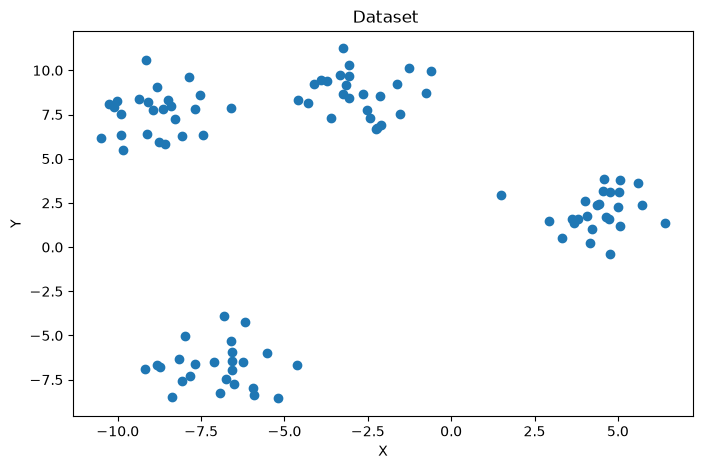

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["X"],
    df["Y"]
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title(" Dataset")

plt.show()

In [ ]:
from scipy.spatial.distance import pdist, squareform

distances = pdist(X, metric="euclidean")

distance_matrix = squareform(distances)

pd.DataFrame(
    distance_matrix[:5, :5]
)

,0,1,2,3,4
0,0.000000,2.354644,1.465119,2.432574,0.487402
1,2.354644,0.000000,2.948225,0.139867,2.673005
2,1.465119,2.948225,0.000000,2.958860,1.060248
3,2.432574,0.139867,2.958860,0.000000,2.732931
4,0.487402,2.673005,1.060248,2.732931,0.000000


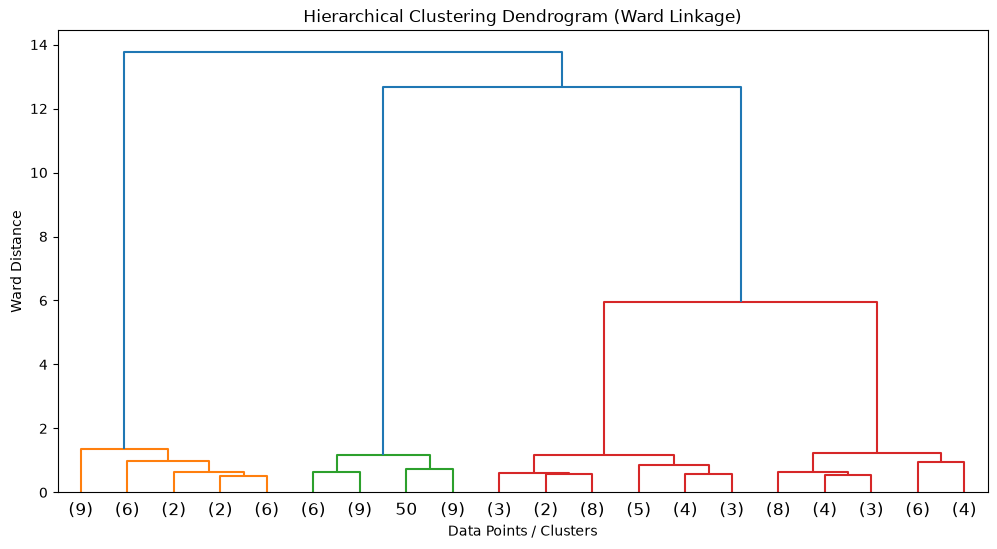

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(
    X,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=20
)

plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Ward Distance")

plt.show()

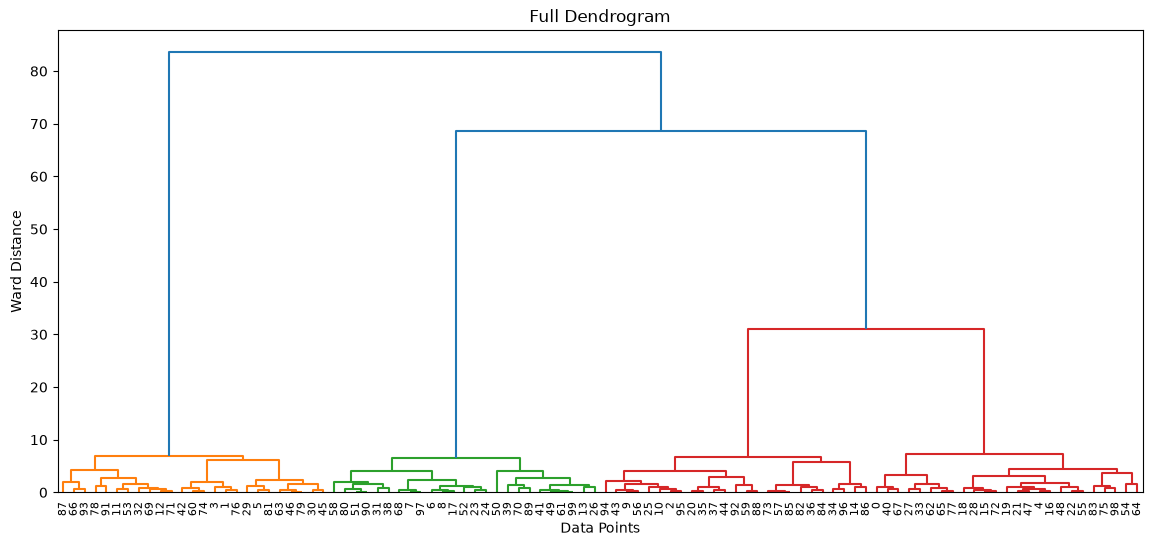

In [5]:
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Full Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Ward Distance")

plt.show()

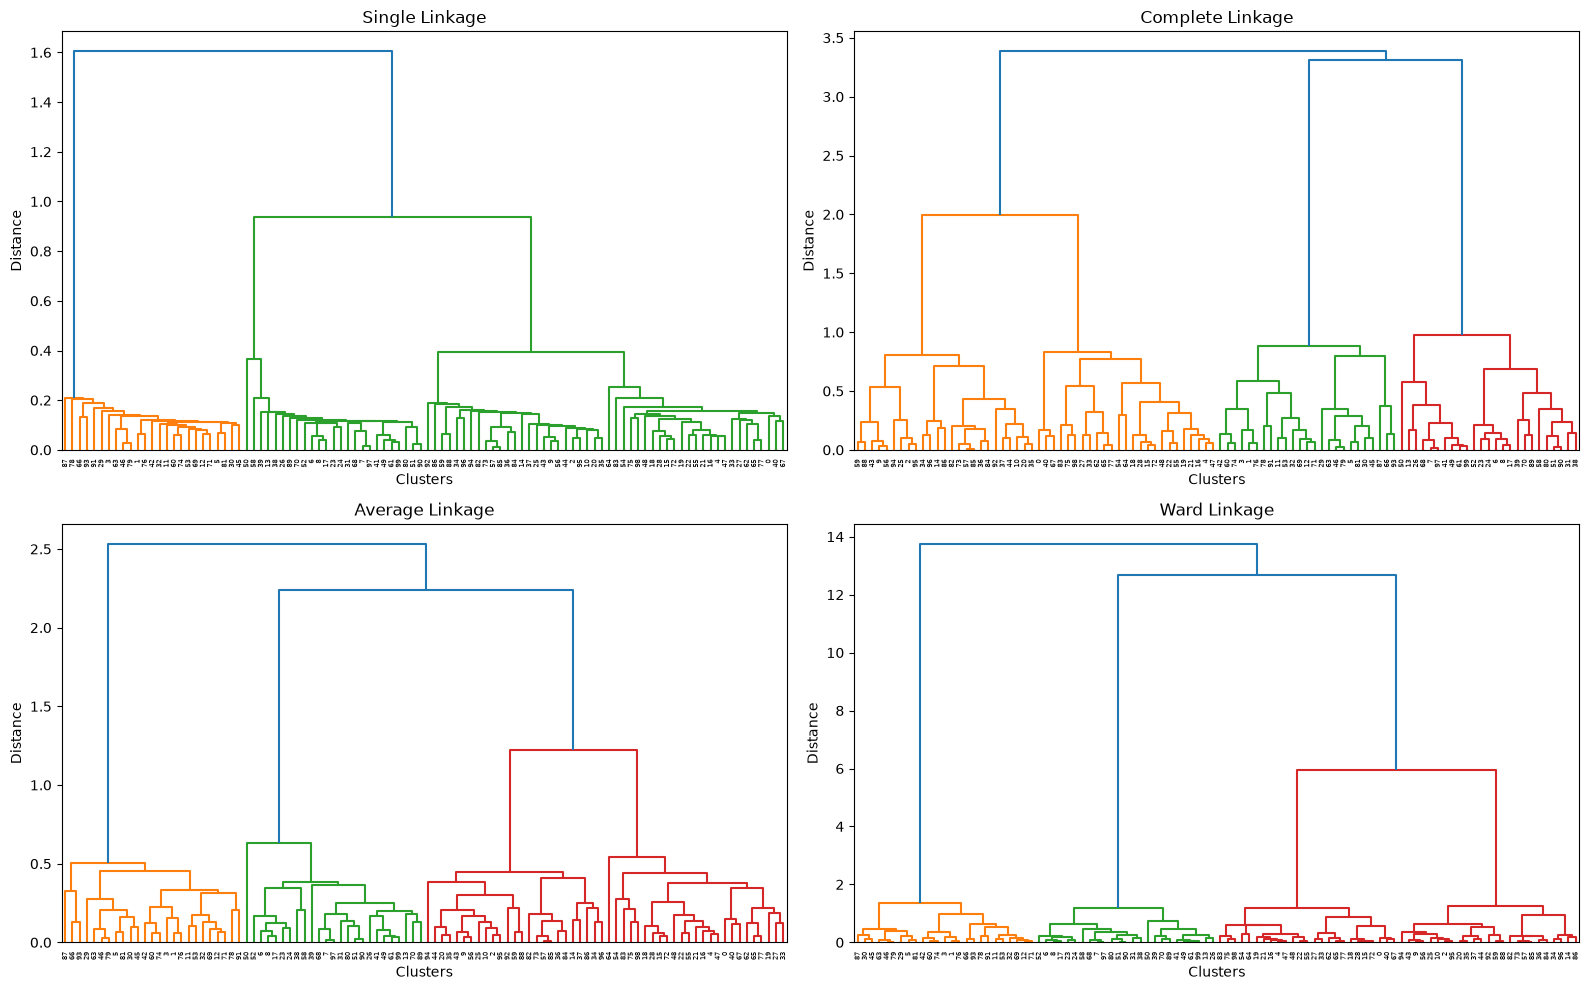

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_methods = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

for method, ax in zip(linkage_methods, axes.flatten()):

    Z_method = linkage(
        X,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z_method,
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Clusters")
    ax.set_ylabel("Distance")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.cluster import AgglomerativeClustering

linkage_methods = ["single", "complete", "average", "ward"]
k_values = [3, 4]

results = {}

for method in linkage_methods:

    for k in k_values:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        results[(method, k)] = labels

        print(f"Linkage: {method}, K: {k}")
        print(pd.Series(labels).value_counts().sort_index())
        print("-" * 40)

Linkage: single, K: 3
0    50
1    25
2    25
Name: count, dtype: int64
----------------------------------------
Linkage: single, K: 4
0    25
1    25
2    25
3    25
Name: count, dtype: int64
----------------------------------------
Linkage: complete, K: 3
0    50
1    25
2    25
Name: count, dtype: int64
----------------------------------------
Linkage: complete, K: 4
0    25
1    25
2    25
3    25
Name: count, dtype: int64
----------------------------------------
Linkage: average, K: 3
0    50
1    25
2    25
Name: count, dtype: int64
----------------------------------------
Linkage: average, K: 4
0    25
1    25
2    25
3    25
Name: count, dtype: int64
----------------------------------------
Linkage: ward, K: 3
0    50
1    25
2    25
Name: count, dtype: int64
----------------------------------------
Linkage: ward, K: 4
0    25
1    25
2    25
3    25
Name: count, dtype: int64
----------------------------------------


In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from scipy.spatial.distance import cdist

results_df = []

linkage_methods = ["single", "complete", "average", "ward"]
k_values = [3, 4]

for method in linkage_methods:

    for k in k_values:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        sil_score = silhouette_score(
            X,
            labels,
            metric="euclidean"
        )
        wcss = 0

        for cluster in np.unique(labels):

            cluster_points = X[labels == cluster]

            centroid = cluster_points.mean(axis=0)

            squared_distances = np.sum(
                (cluster_points - centroid) ** 2,
                axis=1
            )

            wcss += squared_distances.sum()

        results_df.append({
            "Linkage": method,
            "K": k,
            "Silhouette Score": sil_score,
            "WCSS": wcss
        })

results_df = pd.DataFrame(results_df)

results_df.sort_values(
    by="Silhouette Score",
    ascending=False
).reset_index(drop=True)

,Linkage,K,Silhouette Score,WCSS
0,single,4,0.761466,7.502120
1,complete,4,0.761466,7.502120
2,ward,4,0.761466,7.502120
3,average,4,0.761466,7.502120
4,complete,3,0.722355,25.197993
5,single,3,0.722355,25.197993
6,average,3,0.722355,25.197993
7,ward,3,0.722355,25.197993


In [ ]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward",
    metric="euclidean"
)

df["Cluster"] = model.fit_predict(X)

df.head()

,X,Y,Cluster
0,-9.854480,5.505706,3
1,-5.903407,-8.357147,0
2,-3.072567,9.665358,1
3,-5.196274,-8.562331,0
4,-8.408983,7.996464,3


In [ ]:
cluster_profile = df.groupby("Cluster").mean()

cluster_profile

,X,Y
Cluster,,
0,-6.994011,-6.741642
1,-2.736087,8.689246
2,4.405325,2.030832
3,-8.857869,7.592994
